> ✅ **Completed by Ketan Khanna**

> Machine Learning · University of Toronto School of Continuing Studies · Winter 2022 · Week 4

> 🤖 Includes a section **completed afterwards with Claude (2026)**, clearly marked at the end. Everything above it is the original work.

In [23]:
"""# Assignment for Module 4: Clustering

## Description

In this assignment you will study the electric demand (power) of clients in Portugal, during 2013 and 2014.

The data$^1$ available contains 370 time series, corresponding to the electric demand$^2$ for 370 clients, between 2011 and 2014. 

In this guided exercise you will use clustering techniques to understand the typical behaviour during 2013-2014.

#### 1. Data:
https://archive.ics.uci.edu/ml/datasets/ElectricityLoadDiagrams20112014#

#### 2. Electric Demand:
http://www.think-energy.net/KWvsKWH.htm"""



'# Assignment for Module 4: Clustering\n\n## Description\n\nIn this assignment you will study the electric demand (power) of clients in Portugal, during 2013 and 2014.\n\nThe data$^1$ available contains 370 time series, corresponding to the electric demand$^2$ for 370 clients, between 2011 and 2014. \n\nIn this guided exercise you will use clustering techniques to understand the typical behaviour during 2013-2014.\n\n#### 1. Data:\nhttps://archive.ics.uci.edu/ml/datasets/ElectricityLoadDiagrams20112014#\n\n#### 2. Electric Demand:\nhttp://www.think-energy.net/KWvsKWH.htm'

In [24]:
"""## Data Preparation

Start by downloading the data to a local directory and modify the "pathToFile" and "fileName" variables, if needed"""

'## Data Preparation\n\nStart by downloading the data to a local directory and modify the "pathToFile" and "fileName" variables, if needed'

In [25]:
fileName = 'LD2011_2014.txt'
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import random
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
random.seed(42)

# Replace "," by ".", otherwise the numbers will be in the form 2,3445 instead of 2.3445
import fileinput

with fileinput.FileInput(fileName, inplace=True, backup='.bak') as file:
    for line in file:
        print(line.replace(",", "."), end='')

In [26]:
# Create dataframe
import pandas as pd
data = pd.read_csv(fileName, sep=";", index_col=0)

In [27]:
### Quick data inspection

In [28]:
data

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2011-01-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 00:30:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 00:45:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 01:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-10-25 01:30:00,1.269036,19.203414,1.737619,103.658537,35.365854,133.928571,4.522329,232.323232,38.461538,43.010753,...,100.642398,22800.0,831.223629,1136.363636,43.024772,11.117613,758.560140,115.191987,798.387097,18162.162162
2014-10-25 01:45:00,2.538071,19.203414,1.737619,99.593496,35.365854,122.023810,3.391747,215.488215,40.209790,44.086022,...,94.932191,22700.0,780.590717,1113.636364,44.328553,8.777063,784.899034,105.175292,799.120235,19891.891892
2014-10-25 02:00:00,1.269036,17.069701,1.737619,97.560976,36.585366,125.000000,3.391747,198.653199,40.209790,47.311828,...,94.218415,22300.0,780.590717,1136.363636,45.632334,8.777063,753.292362,101.836394,817.448680,18864.864865
2014-10-25 02:15:00,2.538071,17.780939,1.737619,89.430894,40.243902,125.000000,3.391747,195.286195,41.958042,44.086022,...,80.656674,18100.0,755.274262,1068.181818,44.328553,9.947338,685.689201,93.489149,876.832845,18918.918919


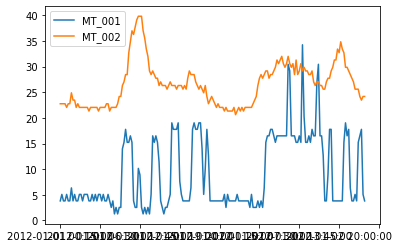

In [29]:
data_example = data.loc['2012-01-01 00:15:00':'2012-01-03 00:00:00'][['MT_001','MT_002']]
data_example.plot()
plt.show()

In [30]:
data.iloc[:,256].mean() # Question 1

157.7932325068089

In [31]:
data2011 = data.loc['2011-01-01 00:15:00':'2012-01-01 00:00:00']
data2012 = data.loc['2012-01-01 00:15:00':'2013-01-01 00:00:00']
data2013 = data.loc['2013-01-01 00:15:00':'2014-01-01 00:00:00']
data2014 = data.loc['2014-01-01 00:15:00':'2015-01-01 00:00:00']

In [32]:
# Check number of days
print(data2011.shape[0]/96)
print(data2012.shape[0]/96)
print(data2013.shape[0]/96)
print(data2014.shape[0]/96)

365.0
366.0
365.0
297.1041666666667


In [33]:
# See number of clients with 0 demand per year
print(sum(data2011.mean()==0))
print(sum(data2012.mean()==0))
print(sum(data2013.mean()==0))
print(sum(data2014.mean()==0))

210
37
21
1


In [34]:
clients = data2011.columns
clients_no_demand = clients[data2013.mean()==0] # clients with 0 demand
data_13_14 = data2013.append(data2014) # appending 2013 and 2014
data_13_14 = data_13_14.drop(clients_no_demand, axis=1) # drop clients with 0 demand
print(data_13_14.shape)
print(sum(data_13_14.mean()==0)) # check that there are no clients with 0 demand

(63562, 349)
0


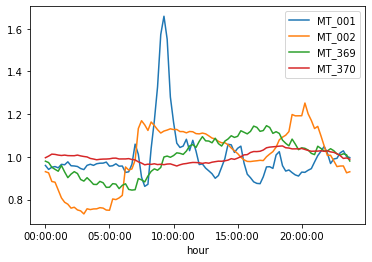

In [35]:
data = data_13_14.copy() # weekdays weekends, data2011, data2012, data2013, data2014
data['hour'] = data.index.map(lambda x: x[11:])
datagrouped = data.groupby("hour")
average_curves = datagrouped.agg("mean")
average_curves.shape 
average_curves_norm = average_curves/(average_curves.mean())
average_curves_norm[['MT_001','MT_002','MT_369','MT_370']].plot()
plt.show()

In [36]:
X = average_curves_norm.copy()
X = np.array(X.T) # put it on the right format

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
#Set number of clusters at initialisation time
k_means = KMeans(n_clusters=2)
model = k_means.fit(X)
k_means.inertia_   # for problem 2, put n_clusters = 1/2 for result

1180.3812571551414

In [38]:
k_means = KMeans(n_clusters=5)
model = k_means.fit(X)
score = silhouette_score(X, k_means.labels_, metric='euclidean')
score

0.4353870588454734

In [39]:
k_means = KMeans(n_clusters=6)
model = k_means.fit(X)
score = silhouette_score(X, k_means.labels_, metric='euclidean')
score

0.4253478661205236

C:\Users\user\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:881: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


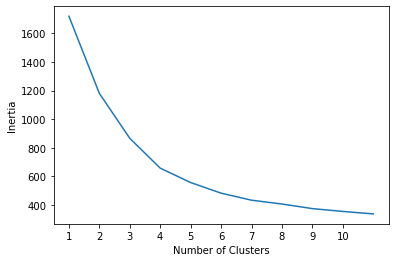

In [40]:
# plotting the inertia chart

inertia_val = []
for i in range(1,12):
    k_means = KMeans(n_clusters=i)
    model = k_means.fit(X)
    inertia_val.append(k_means.inertia_)

plt.plot(range(1, 12), inertia_val)
plt.xticks(range(1, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

In [43]:
client = 'MT_022'
oneClient = data_13_14[client]
X = [] # a list of arrays, each array being a normalized curve for a day
for J in range(2*365):
    X.extend([np.array(oneClient[J*96:(J+1)*96])])#/np.mean(oneClient[J*96:(J+1)*96])])
oneClient

2013-01-01 00:15:00    31.133250
2013-01-01 00:30:00    28.642590
2013-01-01 00:45:00    27.397260
2013-01-01 01:00:00    24.906600
2013-01-01 01:15:00    24.283935
                         ...    
2014-10-25 01:30:00    17.434620
2014-10-25 01:45:00    16.811955
2014-10-25 02:00:00    16.811955
2014-10-25 02:15:00    15.566625
2014-10-25 02:30:00    16.189290
Name: MT_022, Length: 63562, dtype: float64

In [45]:
# plotting the inertia chart

inertia_val = []
for i in range(1,12):
    k_means = KMeans(n_clusters=i)
    model = k_means.fit(X)
    inertia_val.append(k_means.inertia_)

plt.plot(range(1, 12), inertia_val)
plt.xticks(range(1, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (730,) + inhomogeneous part.

In [ ]:
from datetime import date, timedelta

d1 = date(2013, 1, 1)  # start date
d2 = date(2014, 12, 31)  # end date
delta = d2 - d1         # timedelta
daysyear = []
D = {0:'mon', 1:'tue', 2:'wed', 3:'thu', 4:'fri', 5:'sat', 6:'sun'}
for i in range(delta.days + 1):
    daysyear.extend([D[(d1 + timedelta(days=i)).weekday()]+"-"+str(d1 + timedelta(days=i))])

In [ ]:
D

In [ ]:
k_means = KMeans(n_clusters=2)
model = k_means.fit(X)
centroids = k_means.cluster_centers_

---
## 🤖 Completed afterwards with Claude (2026)
Everything above this line is Ketan's original coursework. The cells below were added in 2026 with Claude to finish questions that were left open, and are kept separate so it's clear who did what.

The one-client daily clustering above hit an error: 2014 only has ~297 days of data, so slicing 730 days produced empty arrays at the end. This finishes that part using the days that exist and labels each cluster by weekday vs weekend.

662 complete days of 96 quarter-hour readings


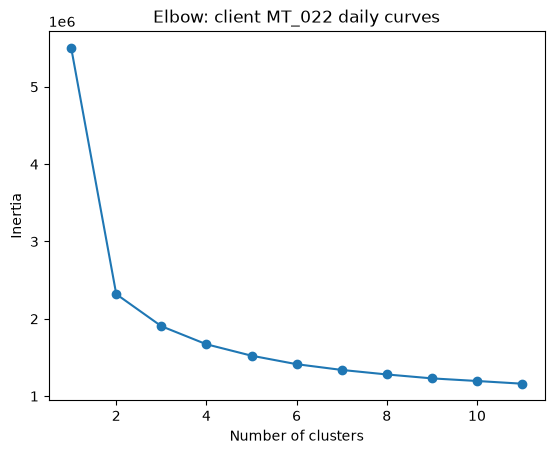

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans

data = pd.read_csv('LD2011_2014.txt', sep=';', index_col=0, usecols=[0, 22])  # just client MT_022
data.index = pd.to_datetime(data.index)
one = data.loc['2013-01-01 00:15':'2015-01-01 00:00', 'MT_022']
daily = one.groupby(one.index.map(lambda t: (t - pd.Timedelta(minutes=15)).date())).apply(np.array)
daily = daily[daily.map(len) == 96]
X = np.vstack(daily.values)
print(f'{X.shape[0]} complete days of 96 quarter-hour readings')

inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 12)]
plt.plot(range(1, 12), inertia, marker='o'); plt.xlabel('Number of clusters'); plt.ylabel('Inertia'); plt.title('Elbow: client MT_022 daily curves'); plt.show()

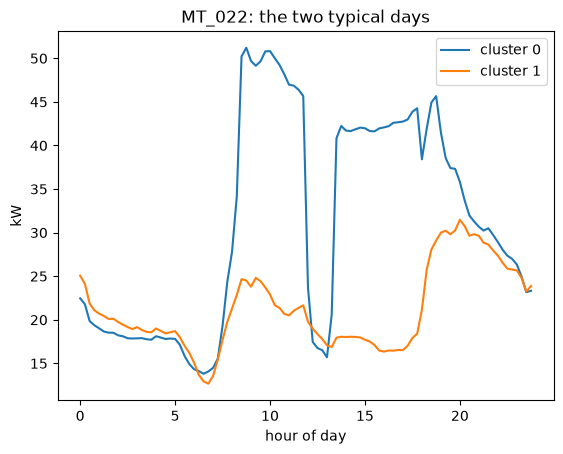

day type  weekday  weekend
cluster                   
0             422       37
1              52      151


In [2]:
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X)
hours = np.arange(96) / 4
for i, c in enumerate(km.cluster_centers_):
    plt.plot(hours, c, label=f'cluster {i}')
plt.xlabel('hour of day'); plt.ylabel('kW'); plt.legend(); plt.title('MT_022: the two typical days'); plt.show()

wd = pd.Series(pd.to_datetime(daily.index).dayofweek, index=daily.index)
print(pd.crosstab(km.labels_, wd.map(lambda d: 'weekend' if d >= 5 else 'weekday').values, rownames=['cluster'], colnames=['day type']))

Two clusters capture the main split (most of the inertia drop comes early in the elbow chart), and the two centroids are a high-demand profile with a daytime plateau and a low, flatter profile. The crosstab shows the split lines up with the calendar: one cluster is almost all weekdays and the other mostly weekends and holidays, so this client behaves like a business that runs on working days.